# Reserve price experiment: VCG, GSP, BB and RBB (sync, async and more)

A full factorial study of how a per-click reserve `r` changes **revenue**, **efficiency** and the **equilibrium structure**.

**Factors**
| Factor | Levels (edit in cell 1) |
|---|---|
| Bidders / slots `(n, k)` | n = k and n > k |
| Value distribution | uniform, lognormal, exponential |
| CTR decay `theta_s = decay**s` | steep, medium, flat |
| Initial bids | truthful, zero, random |
| Rule | BB, RBB |
| Update scheduler | `sync`, `async-rand` (random order), `async-rr` (fixed round-robin), `hybrid` (each player moves w.p. q on a stale snapshot) |
| Reserve | 10 quantile levels of the value distribution, plus the Myerson reserve `r*` |

**Benchmarks:** VCG (truthful) and the GSP symmetric equilibrium (GSP-SNE), both with the reserve.

**Cells:** 1 setup, 2 primitives and benchmarks, 3 dynamics, 4 run the experiment, 5 overview, 6 revenue curves, 7 optimal reserve, 8 stability, 9 revenue and efficiency vs benchmarks, 10 factor effects, 11 equilibrium multiplicity, 12 save.

In [1]:
import itertools, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- experiment design (edit freely) -----
PAIRS     = [(3, 3), (5, 5), (6, 4)]            # (n bidders, k slots); n > k adds outsiders
DISTS     = ["uniform", "lognormal", "exponential"]
DECAYS    = [0.5, 0.7, 0.9]                      # theta_s = decay**s
INITS     = ["truthful", "zero", "random"]
RULES     = {"BB": False, "RBB": True}           # name -> restricted?
SCHEDS    = ["sync", "async-rand", "async-rr", "hybrid"]
HYBRID_Q  = 0.5                                  # activation probability for "hybrid"
RQ_LEVELS = np.linspace(0, 0.9, 10)              # reserve grid as quantiles of pooled values

N_DRAWS    = 20      # value profiles per scenario (raise for tighter error bars)
MAX_ROUNDS = 60
TOL        = 1e-9
SEED       = 0
OUT        = -1.0    # bid of a player who stays out of the auction
N_JOBS     = -1      # -1 = all cores; 1 = serial

# Quick smoke test: uncomment to shrink the design
# PAIRS, DISTS, DECAYS, INITS, N_DRAWS = [(5, 5)], ["uniform"], [0.7], ["truthful"], 5

In [2]:
# ----- primitives and benchmarks (reserve r applied to the per-click bid) -----

def draw_values(rng, dist, n):
    if dist == "uniform":
        return rng.uniform(0, 1, n)
    if dist == "lognormal":
        return rng.lognormal(0.0, 0.5, n)
    if dist == "exponential":
        return rng.exponential(1.0, n)
    raise ValueError(dist)

_RSTAR = {}
def myerson_reserve(dist):
    # root of phi(v) = v - (1 - F(v)) / f(v); per-click Myerson reserve for iid values
    if dist in _RSTAR:
        return _RSTAR[dist]
    if dist == "uniform":
        r = 0.5
    elif dist == "exponential":
        r = 1.0
    else:  # lognormal(0, 0.5), solved numerically
        s = 0.5
        g = np.linspace(0.01, 8, 40000)
        pdf = np.exp(-np.log(g) ** 2 / (2 * s * s)) / (g * s * math.sqrt(2 * math.pi))
        cdf = 0.5 * (1 + np.array([math.erf(math.log(x) / (s * math.sqrt(2))) for x in g]))
        phi = g - (1 - cdf) / pdf
        r = float(g[np.argmax(phi >= 0)])
    _RSTAR[dist] = r
    return r

def sorted_eligible(bids, r):
    return np.sort(bids[bids >= r])[::-1]

def price_ladder(e, r, k):
    # q[t] = (t+1)-th highest eligible bid, or r if there is none; length k+1
    q = np.full(k + 1, float(r))
    m = min(len(e), k + 1)
    q[:m] = e[:m]
    return q

def gsp_revenue(bids, r, theta):
    k = len(theta)
    e = sorted_eligible(bids, r)
    q = price_ladder(e, r, k)
    m = min(len(e), k)
    return float(np.sum(theta[:m] * q[1:m + 1]))

def vcg_revenue(values, r, theta):
    # VCG with the reserve modelled as dummy bidders of value r filling empty slots
    k = len(theta)
    e = sorted_eligible(values, r)
    q = price_ladder(e, r, k)
    m = min(len(e), k)
    th = np.append(theta, 0.0)
    inc = th[:-1] - th[1:]
    pay = np.cumsum((inc * q[1:])[::-1])[::-1]
    return float(pay[:m].sum())

def gsp_sne_revenue(values, r, theta):
    # symmetric (locally envy-free) equilibrium of GSP with reserve
    k = len(theta)
    e = sorted_eligible(values, r)
    m = min(len(e), k)
    q = price_ladder(e, r, k)
    b = np.empty(k + 1)
    b[k] = q[k]
    for s in range(k - 1, -1, -1):
        if s < m:
            tp = theta[s - 1] if s > 0 else 2 * theta[0]
            b[s] = e[s] - (theta[s] / tp) * (e[s] - b[s + 1])
        else:
            b[s] = r
    return float(np.sum(theta[:m] * b[1:m + 1]))

def outcome(bids, values, r, theta):
    # revenue, welfare efficiency (vs. no-reserve optimum), filled slots
    k = len(theta)
    elig = np.where(bids >= r)[0]
    order = elig[np.lexsort((elig, -bids[elig]))][:k]
    welfare = np.sum(theta[:len(order)] * values[order])
    opt = np.sum(theta * np.sort(values)[::-1][:k])
    return gsp_revenue(bids, r, theta), welfare / opt, len(order)

In [3]:
# ----- BB / RBB with a reserve, under four update schedulers -----

def others_prices(bids, j, r, k):
    others = np.delete(bids, j)
    e = np.sort(others[others >= r])[::-1]
    p = np.full(k, float(r))
    m = min(len(e), k)
    p[:m] = e[:m]
    return p

def current_slot(bids, j, r, k):
    if bids[j] < r:
        return None
    ahead = np.sum(bids > bids[j]) + np.sum(bids[:j] == bids[j])
    return int(ahead) if ahead < k else None

def respond(bids, j, v, r, theta, restricted):
    k = len(theta)
    p = others_prices(bids, j, r, k)
    util = theta * (v - p)
    s0 = current_slot(bids, j, r, k)
    allowed = np.arange(k) if (not restricted or s0 is None) else np.arange(s0, k)
    s = allowed[np.argmax(util[allowed])]
    if util[s] <= 0:
        return OUT
    tp = theta[s - 1] if s > 0 else 2 * theta[0]   # theta_0 = 2*theta_1 convention
    return v - (theta[s] / tp) * (v - p[s])

def init_bids(values, init, rng):
    if init == "truthful":
        return values.copy()
    if init == "zero":
        return np.zeros(len(values))
    return rng.uniform(0, 1, len(values)) * values

def run_dynamics(values, r, theta, restricted, sched, init, rng,
                 max_rounds=MAX_ROUNDS, tol=TOL):
    # returns (final bids, converged, rounds, detected cycle length (sync only))
    n = len(values)
    b = init_bids(values, init, rng)
    seen = {}
    for t in range(max_rounds):
        if sched in ("sync", "hybrid"):
            resp = np.array([respond(b, j, values[j], r, theta, restricted) for j in range(n)])
            if np.max(np.abs(resp - b)) < tol:          # b is a fixed point
                return b, True, t, 0
            if sched == "sync":
                b = resp
                key = tuple(np.round(b, 8))
                if key in seen:
                    return b, False, t + 1, t - seen[key]
                seen[key] = t
            else:
                b = np.where(rng.random(n) < HYBRID_Q, resp, b)
        else:
            order = rng.permutation(n) if sched == "async-rand" else range(n)
            change = 0.0
            for j in order:
                new = respond(b, j, values[j], r, theta, restricted)
                change = max(change, abs(new - b[j]))
                b[j] = new
            if change < tol:
                return b, True, t + 1, 0
    return b, False, max_rounds, np.nan

In [4]:
# ----- run the full experiment (scenario-level parallelism) -----
COLS = ["n", "k", "dist", "decay", "init", "rq", "r", "is_star", "draw", "mech", "rule",
        "sched", "revenue", "efficiency", "filled", "converged", "rounds", "cycle"]

def run_scenario(spec):
    n, k, dist, decay, init = spec
    theta = decay ** np.arange(k)
    di = DISTS.index(dist)
    ii = INITS.index(init)
    rng = np.random.default_rng([SEED, n, k, di])          # same draws across decay / init
    profiles = [draw_values(rng, dist, n) for _ in range(N_DRAWS)]
    pooled = np.concatenate(profiles)
    grid = list(np.quantile(pooled, RQ_LEVELS))
    grid[0] = 0.0
    rlist = [(rq, r, False) for rq, r in zip(RQ_LEVELS, grid)] + [(np.nan, myerson_reserve(dist), True)]
    rows = []
    for ri, (rq, r, star) in enumerate(rlist):
        for d, v in enumerate(profiles):
            _, eff, filled = outcome(v, v, r, theta)
            head = (n, k, dist, decay, init, rq, r, star, d)
            rows.append(head + ("VCG", "-", "-", vcg_revenue(v, r, theta), eff, filled, True, 0, 0))
            rows.append(head + ("GSP-SNE", "-", "-", gsp_sne_revenue(v, r, theta), eff, filled, True, 0, 0))
            for rule, restricted in RULES.items():
                for si, sched in enumerate(SCHEDS):
                    rr = np.random.default_rng([SEED, n, k, di, int(decay * 100), ii, ri, d, si,
                                                int(restricted)])
                    b, conv, nr, cyc = run_dynamics(v, r, theta, restricted, sched, init, rr)
                    rev, e2, f2 = outcome(b, v, r, theta)
                    rows.append(head + (f"{rule}-{sched}", rule, sched, rev, e2, f2, conv, nr, cyc))
    return rows

specs = list(itertools.product(PAIRS, DISTS, DECAYS, INITS))
specs = [(p[0], p[1], dist, decay, init) for (p, dist, decay, init) in specs]
print(f"{len(specs)} scenarios x {len(RQ_LEVELS) + 1} reserves x {N_DRAWS} draws "
      f"x {2 + len(RULES) * len(SCHEDS)} mechanisms")

t0 = time.time()
try:
    from joblib import Parallel, delayed
    results = Parallel(n_jobs=N_JOBS)(delayed(run_scenario)(s) for s in specs)
except ImportError:
    results = [run_scenario(s) for s in specs]
df = pd.DataFrame([row for res in results for row in res], columns=COLS)
df["pair"] = df.n.astype(str) + "x" + df.k.astype(str)
print(f"done in {time.time() - t0:.0f}s, {len(df):,} rows")

81 scenarios x 11 reserves x 20 draws x 10 mechanisms
done in 77s, 178,200 rows


In [5]:
# ----- overview: convergence of every rule x scheduler, overall and by factor -----
dyn = df[df.rule != "-"]
print("Convergence rate (all scenarios, all reserves)")
print(dyn.groupby(["rule", "sched"])["converged"].mean().unstack().round(3).to_string())

for factor in ["pair", "dist", "decay", "init"]:
    print(f"\nConvergence rate by {factor}")
    print(dyn.groupby([factor, "mech"])["converged"].mean().unstack().round(3).to_string())

Convergence rate (all scenarios, all reserves)
sched  async-rand  async-rr  hybrid   sync
rule                                      
BB          0.918     0.918   0.918  0.879
RBB         0.918     0.918   0.918  0.918

Convergence rate by pair
mech  BB-async-rand  BB-async-rr  BB-hybrid  BB-sync  RBB-async-rand  RBB-async-rr  RBB-hybrid  RBB-sync
pair                                                                                                    
3x3           1.000        1.000      1.000    0.988           1.000         1.000       1.000     1.000
5x5           1.000        1.000      1.000    0.918           1.000         1.000       1.000     1.000
6x4           0.754        0.754      0.754    0.733           0.754         0.754       0.754     0.754

Convergence rate by dist
mech         BB-async-rand  BB-async-rr  BB-hybrid  BB-sync  RBB-async-rand  RBB-async-rr  RBB-hybrid  RBB-sync
dist                                                                                        

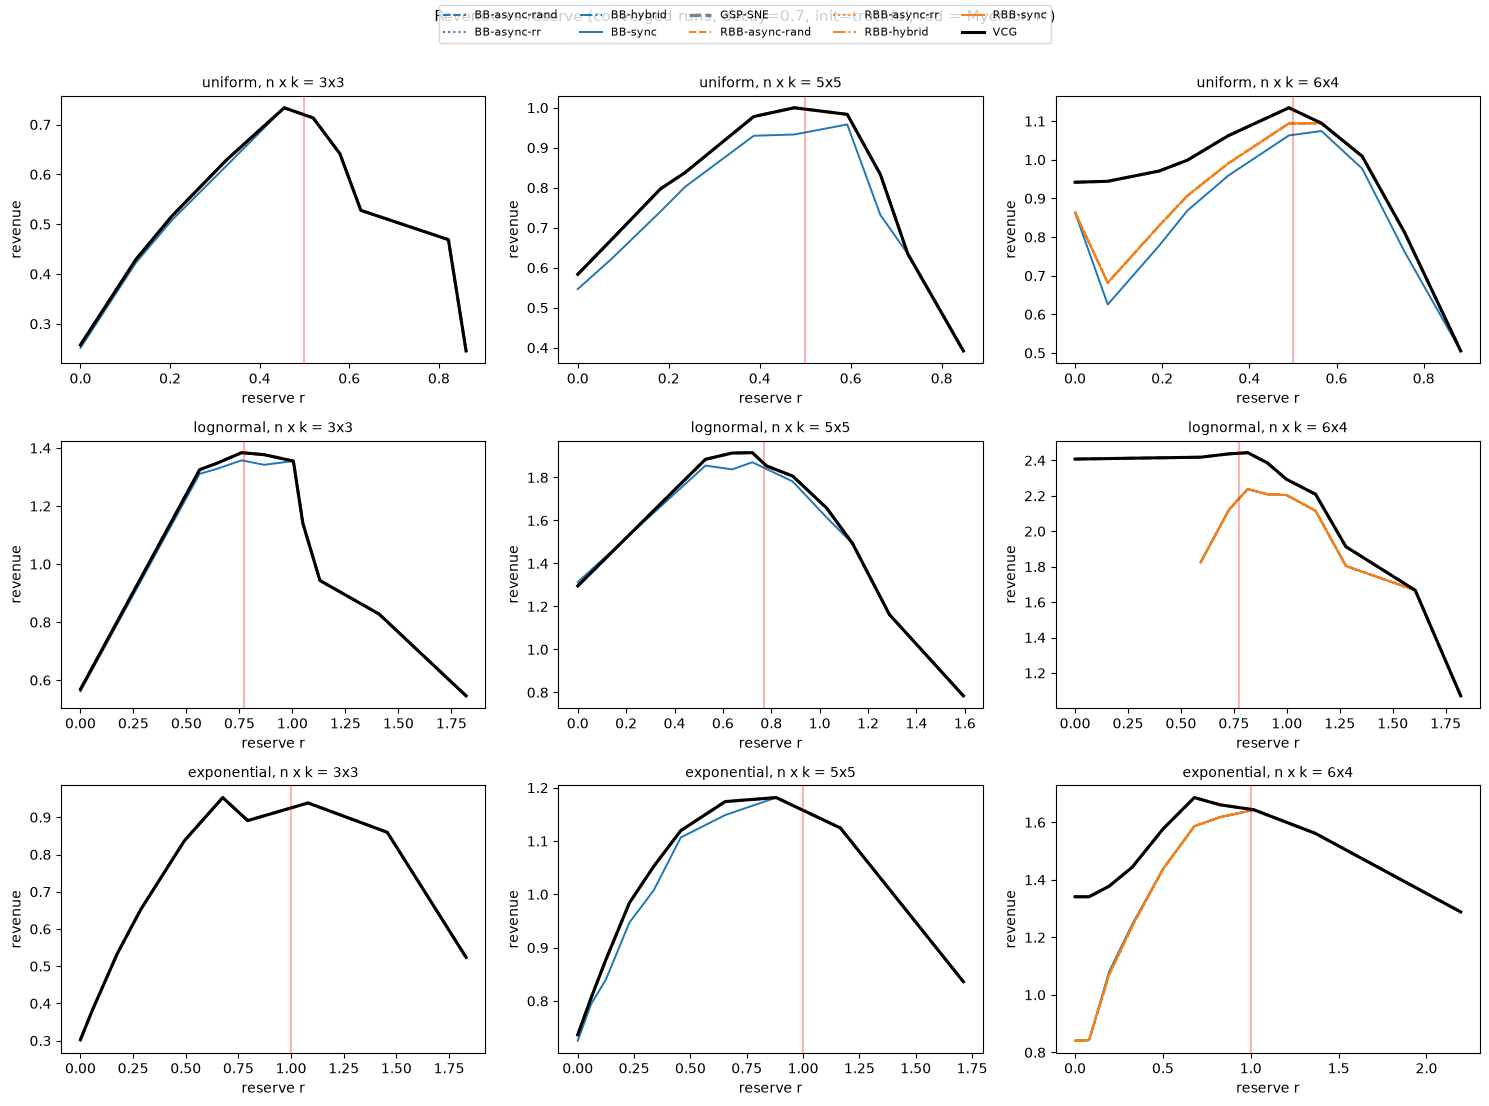

In [6]:
# ----- revenue vs reserve: facets by distribution (rows) and (n, k) (columns) -----
PLOT_DECAY = 0.7
PLOT_INIT = "truthful"

COLORS = {"BB": "tab:blue", "RBB": "tab:orange"}
LSTYLE = {"sync": "-", "async-rand": "--", "async-rr": ":", "hybrid": "-."}

def style(mech):
    if mech == "VCG":
        return dict(color="black", lw=2.2)
    if mech == "GSP-SNE":
        return dict(color="gray", lw=2.2, ls="--")
    rule, sched = mech.split("-", 1)
    return dict(color=COLORS[rule], ls=LSTYLE[sched], lw=1.4)

sub = df[(df.decay == PLOT_DECAY) & (df.init == PLOT_INIT) & (~df.is_star) & df.converged]
fig, axes = plt.subplots(len(DISTS), len(PAIRS), figsize=(5 * len(PAIRS), 3.6 * len(DISTS)),
                         squeeze=False)
for i, dist in enumerate(DISTS):
    for j, pair in enumerate(sorted(df.pair.unique(), key=lambda s: tuple(map(int, s.split("x"))))):
        ax = axes[i, j]
        g = sub[(sub.dist == dist) & (sub.pair == pair)]
        for mech, gm in g.groupby("mech"):
            c = gm.groupby("rq").agg(r=("r", "mean"), rev=("revenue", "mean"))
            ax.plot(c.r, c.rev, **style(mech), label=mech)
        ax.axvline(myerson_reserve(dist), color="red", alpha=0.3)
        ax.set_title(f"{dist}, n x k = {pair}", fontsize=10)
        ax.set_xlabel("reserve r")
        ax.set_ylabel("revenue")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, fontsize=8)
fig.suptitle(f"Revenue vs reserve (converged runs, decay={PLOT_DECAY}, init={PLOT_INIT}; red = Myerson r*)",
             y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

In [7]:
# ----- optimal reserve: grid optimum vs Myerson, and lift at r* over no reserve -----
conv = df[df.converged]
keys = ["pair", "dist", "decay", "init", "mech"]

by_r = conv.groupby(keys + ["r"]).revenue.mean().reset_index()
best = by_r.loc[by_r.groupby(keys).revenue.idxmax()]
tab = best.pivot_table(index=["pair", "dist", "decay"], columns="mech", values="r", aggfunc="mean")
tab.insert(0, "Myerson r*", [myerson_reserve(d) for d in tab.index.get_level_values("dist")])
print("Revenue-maximizing reserve on the grid (mean over init), compare with Myerson r*")
print(tab.round(2).to_string())

rev0 = conv[conv.rq == 0].groupby(["pair", "dist", "mech"]).revenue.mean()
revs = conv[conv.is_star].groupby(["pair", "dist", "mech"]).revenue.mean()
lift = (100 * (revs / rev0 - 1)).unstack("mech")
print("\nRevenue lift (%) from setting r = r*, relative to r = 0 (mean over decay and init)")
print(lift.round(1).to_string())

Revenue-maximizing reserve on the grid (mean over init), compare with Myerson r*
mech                    Myerson r*  BB-async-rand  BB-async-rr  BB-hybrid  BB-sync  GSP-SNE  RBB-async-rand  RBB-async-rr  RBB-hybrid  RBB-sync   VCG
pair dist        decay                                                                                                                               
3x3  exponential 0.5          1.00           1.00         1.00       1.00     1.00     1.00            1.00          1.00        1.00      1.00  1.00
                 0.7          1.00           1.00         1.00       1.00     1.00     1.00            1.00          1.00        1.00      1.00  1.00
                 0.9          1.00           1.00         1.00       1.00     1.00     1.00            1.00          1.00        1.00      1.00  1.00
     lognormal   0.5          0.77           0.87         0.87       0.87     0.87     0.87            0.87          0.87        0.87      0.87  0.87
                 0.

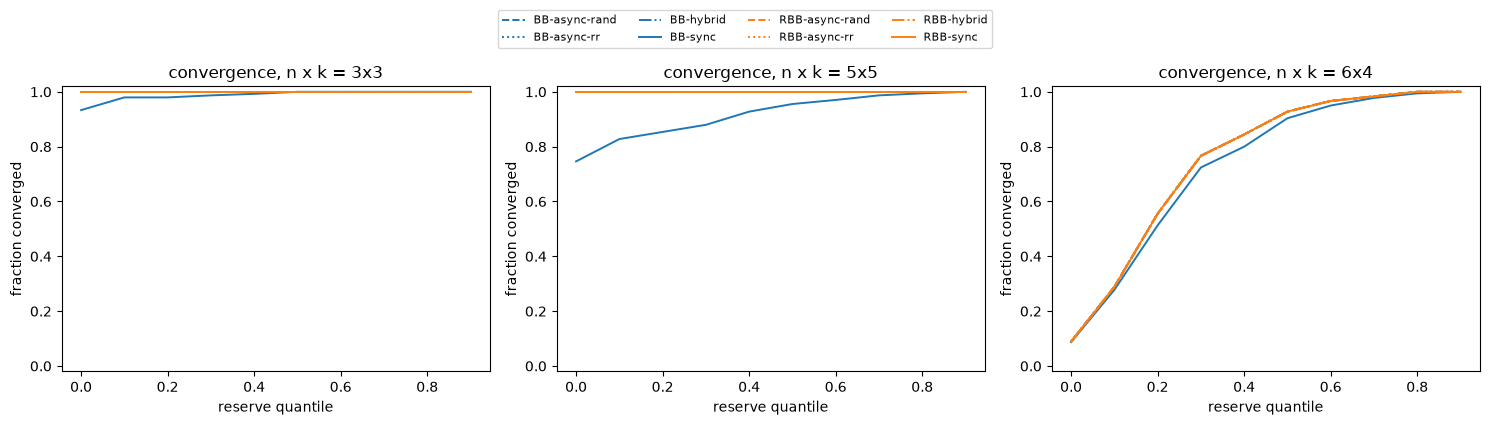

Rounds to converge (converged runs only), mean by mechanism and pair
pair             3x3   5x5   6x4
mech                            
BB-async-rand   2.58  3.30  3.05
BB-async-rr     2.50  3.16  2.94
BB-hybrid       4.61  7.18  6.46
BB-sync         2.03  3.18  2.85
RBB-async-rand  2.58  3.29  3.03
RBB-async-rr    2.52  3.17  2.93
RBB-hybrid      4.57  7.08  6.49
RBB-sync        2.00  3.12  2.78

Sync runs that did not converge: count and mean detected cycle length
           n_runs  mean_cycle
rule pair                    
BB   3x3       69        2.00
     5x5      463        2.31
     6x4     1497        8.59
RBB  6x4     1392        9.99


In [8]:
# ----- stability: convergence vs reserve, cycling, and rounds to converge -----
dyn = df[(df.rule != "-") & (~df.is_star)]
fig, axes = plt.subplots(1, len(PAIRS), figsize=(5 * len(PAIRS), 3.8), squeeze=False)
for j, pair in enumerate(sorted(dyn.pair.unique(), key=lambda s: tuple(map(int, s.split("x"))))):
    ax = axes[0, j]
    for mech, g in dyn[dyn.pair == pair].groupby("mech"):
        c = g.groupby("rq").converged.mean()
        ax.plot(c.index, c.values, **style(mech), label=mech)
    ax.set(title=f"convergence, n x k = {pair}", xlabel="reserve quantile", ylabel="fraction converged",
           ylim=(-0.02, 1.02))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, 1.12))
plt.tight_layout()
plt.show()

print("Rounds to converge (converged runs only), mean by mechanism and pair")
print(dyn[dyn.converged].groupby(["mech", "pair"]).rounds.mean().unstack().round(2).to_string())

cyc = dyn[(dyn.sched == "sync") & (~dyn.converged)]
print("\nSync runs that did not converge: count and mean detected cycle length")
print(cyc.groupby(["rule", "pair"]).agg(n_runs=("draw", "size"), mean_cycle=("cycle", "mean")).round(2).to_string())

In [9]:
# ----- revenue and efficiency of the dynamics relative to the benchmarks -----
mk = ["n", "k", "dist", "decay", "init", "r", "draw"]
sne = df[df.mech == "GSP-SNE"][mk + ["revenue"]].rename(columns={"revenue": "sne"})
vcg = df[df.mech == "VCG"][mk + ["revenue"]].rename(columns={"revenue": "vcg"})
m = df[(df.rule != "-") & df.converged].merge(sne, on=mk).merge(vcg, on=mk)
m["vs_sne"] = np.where(m.sne > 0, m.revenue / m.sne, np.nan)
m["vs_vcg"] = np.where(m.vcg > 0, m.revenue / m.vcg, np.nan)

print("Mean revenue / GSP-SNE revenue (converged runs) by mechanism and pair")
print(m.groupby(["mech", "pair"]).vs_sne.mean().unstack().round(3).to_string())
print("\nMean revenue / VCG revenue (converged runs) by mechanism and pair")
print(m.groupby(["mech", "pair"]).vs_vcg.mean().unstack().round(3).to_string())

print("\nShare of converged runs whose revenue differs from GSP-SNE by more than 1%")
m["off_sne"] = (m.vs_sne - 1).abs() > 0.01
print(m.groupby(["mech", "pair"]).off_sne.mean().unstack().round(3).to_string())

eff = df[df.converged & (~df.is_star)].groupby(["mech", "rq"]).efficiency.mean().unstack()
print("\nWelfare efficiency vs no-reserve optimum, by mechanism and reserve quantile")
print(eff.round(3).to_string())

Mean revenue / GSP-SNE revenue (converged runs) by mechanism and pair
pair            3x3  5x5    6x4
mech                           
BB-async-rand   1.0  1.0  0.996
BB-async-rr     1.0  1.0  0.996
BB-hybrid       1.0  1.0  0.996
BB-sync         1.0  1.0  0.996
RBB-async-rand  1.0  1.0  0.996
RBB-async-rr    1.0  1.0  0.996
RBB-hybrid      1.0  1.0  0.996
RBB-sync        1.0  1.0  0.996

Mean revenue / VCG revenue (converged runs) by mechanism and pair
pair            3x3  5x5    6x4
mech                           
BB-async-rand   1.0  1.0  0.996
BB-async-rr     1.0  1.0  0.996
BB-hybrid       1.0  1.0  0.996
BB-sync         1.0  1.0  0.996
RBB-async-rand  1.0  1.0  0.996
RBB-async-rr    1.0  1.0  0.996
RBB-hybrid      1.0  1.0  0.996
RBB-sync        1.0  1.0  0.996

Share of converged runs whose revenue differs from GSP-SNE by more than 1%
pair            3x3  5x5    6x4
mech                           
BB-async-rand   0.0  0.0  0.068
BB-async-rr     0.0  0.0  0.068
BB-hybrid       0.0

In [10]:
# ----- marginal effect of each factor (mean over all other factors) -----
conv = df[df.converged & (~df.is_star)]
dynall = df[(df.rule != "-") & (~df.is_star)]

for factor in ["pair", "dist", "decay", "init"]:
    print(f"=== {factor} ===")
    t1 = dynall.groupby([factor, "rule"]).converged.mean().unstack().round(3)
    t1.columns = [f"conv_{c}" for c in t1.columns]
    t2 = m.groupby([factor, "rule"]).vs_sne.mean().unstack().round(3)
    t2.columns = [f"rev/SNE_{c}" for c in t2.columns]
    print(pd.concat([t1, t2], axis=1).to_string(), "\n")

=== pair ===
      conv_BB  conv_RBB  rev/SNE_BB  rev/SNE_RBB
pair                                            
3x3     0.997     1.000       1.000        1.000
5x5     0.979     1.000       1.000        1.000
6x4     0.737     0.742       0.996        0.996 

=== dist ===
             conv_BB  conv_RBB  rev/SNE_BB  rev/SNE_RBB
dist                                                   
exponential    0.915     0.920       0.998        0.998
lognormal      0.897     0.906       1.000        1.000
uniform        0.900     0.916       0.999        0.999 

=== decay ===
       conv_BB  conv_RBB  rev/SNE_BB  rev/SNE_RBB
decay                                            
0.5      0.932     0.932       0.998        0.998
0.7      0.904     0.912       0.999        0.999
0.9      0.877     0.898       1.000        1.000 

=== init ===
          conv_BB  conv_RBB  rev/SNE_BB  rev/SNE_RBB
init                                                
random      0.906     0.914       0.999        0.999
truthfu

In [11]:
# ----- equilibrium multiplicity: distinct fixed points across update orders and initial bids -----
def fixed_points(profile, r, theta, restricted, sched, n_orders=12):
    finals, revs = {}, []
    for init in INITS:
        for o in range(n_orders if (sched != "async-rr" or init == "random") else 1):
            rr = np.random.default_rng([SEED + 7, o, INITS.index(init)])
            b, conv, _, _ = run_dynamics(profile, r, theta, restricted, sched, init, rr)
            if conv:
                finals[tuple(np.round(b, 5))] = gsp_revenue(b, r, theta)
    return finals

rows_ = []
rng_m = np.random.default_rng(SEED + 99)
for (n, k) in PAIRS:
    theta = 0.7 ** np.arange(k)
    profs = [draw_values(rng_m, "uniform", n) for _ in range(10)]
    for rq in [0.0, 0.5, 0.9]:
        r = float(np.quantile(np.concatenate(profs), rq)) if rq > 0 else 0.0
        for rule, restricted in RULES.items():
            for sched in ["sync", "async-rand", "async-rr"]:
                res = [fixed_points(p, r, theta, restricted, sched) for p in profs]
                rows_.append(dict(pair=f"{n}x{k}", reserve_q=rq, rule=rule, sched=sched,
                                  mean_distinct_fixed_pts=np.mean([len(x) for x in res]),
                                  frac_profiles_multiple=np.mean([len(x) > 1 for x in res]),
                                  mean_rev_spread=np.mean([(max(x.values()) - min(x.values())) if x else np.nan
                                                           for x in res])))
mult = pd.DataFrame(rows_)
print("Equilibrium multiplicity (uniform values, decay 0.7; orders x initial bids; converged runs only)")
print(mult.round(3).to_string(index=False))

Equilibrium multiplicity (uniform values, decay 0.7; orders x initial bids; converged runs only)
pair  reserve_q rule      sched  mean_distinct_fixed_pts  frac_profiles_multiple  mean_rev_spread
 3x3        0.0   BB       sync                      1.0                     0.0              0.0
 3x3        0.0   BB async-rand                      1.0                     0.0              0.0
 3x3        0.0   BB   async-rr                      1.0                     0.0              0.0
 3x3        0.0  RBB       sync                      1.0                     0.0              0.0
 3x3        0.0  RBB async-rand                      1.0                     0.0              0.0
 3x3        0.0  RBB   async-rr                      1.0                     0.0              0.0
 3x3        0.5   BB       sync                      1.0                     0.0              0.0
 3x3        0.5   BB async-rand                      1.0                     0.0              0.0
 3x3        0.5   BB 

In [12]:
# ----- save results -----
df.to_csv("reserve_experiment_results.csv", index=False)
mult.to_csv("reserve_experiment_multiplicity.csv", index=False)
print("saved reserve_experiment_results.csv and reserve_experiment_multiplicity.csv")
print(df.head())

saved reserve_experiment_results.csv and reserve_experiment_multiplicity.csv
   n  k     dist  decay      init   rq    r  is_star  draw           mech  \
0  3  3  uniform    0.5  truthful  0.0  0.0    False     0            VCG   
1  3  3  uniform    0.5  truthful  0.0  0.0    False     0        GSP-SNE   
2  3  3  uniform    0.5  truthful  0.0  0.0    False     0        BB-sync   
3  3  3  uniform    0.5  truthful  0.0  0.0    False     0  BB-async-rand   
4  3  3  uniform    0.5  truthful  0.0  0.0    False     0    BB-async-rr   

  rule       sched   revenue  efficiency  filled  converged  rounds  cycle  \
0    -           -  0.077155         1.0       3       True       0    0.0   
1    -           -  0.077155         1.0       3       True       0    0.0   
2   BB        sync  0.077155         1.0       3       True       3    0.0   
3   BB  async-rand  0.077155         1.0       3       True       3    0.0   
4   BB    async-rr  0.077155         1.0       3       True       3   